# Wheat hyperspectral pipeline — v6

Run **Stage 0** only to install dependencies. An optional iris-calibration cell precedes Stage 1. Stages **1, 2, 2a and 3** are independent: changes to masks require only Stage 3.

- **1:** dark / ArUco / flat / Spectralon → `corrected_cube.npz`
- **2:** segmentation model: GWFSS SegFormer or interactive SAM
- **2a:** edit existing masks or draw new ones
- **3:** raw and Savitzky–Golay spectra, indices, VI maps, PCA maps, PCA/K-means of objects

Mouse editing requires `%matplotlib widget` (`ipympl`). Avoid `%matplotlib inline` during editing.

## Stage 0 — install libraries (Python 3.13.9)
Run once, then **restart the kernel**.

In [ ]:
# Установка всех внешних библиотек для пайплайна (Python 3.13.9, 64-bit).
# Запустить ОДИН раз в новом окружении Jupyter, затем перезапустить kernel.
# Важно: устанавливаем пакеты в интерпретатор, используемый этим ноутбуком.
import sys
import platform
import subprocess
from importlib.metadata import version, PackageNotFoundError

if sys.version_info[:2] != (3, 13):
    raise RuntimeError(
        f"Требуется Python 3.13.x (проверено для 3.13.9); "
        f"текущая версия: {sys.version.split()[0]}"
    )
if sys.maxsize <= 2**32:
    raise RuntimeError("Необходим 64-битный Python для PyTorch.")

print("Python:", sys.version.split()[0])
print("Interpreter:", sys.executable)

# Выбери способ установки PyTorch:
# 'cpu'   — работает без NVIDIA GPU (самый универсальный вариант)
# 'cu126' — NVIDIA GPU + подходящий драйвер CUDA 12.6
# 'cu130' — NVIDIA GPU + подходящий драйвер CUDA 13.0
# 'cu132' — NVIDIA GPU + подходящий драйвер CUDA 13.2
TORCH_BACKEND = 'cpu'


def pip_install(*packages):
    cmd = [sys.executable, '-m', 'pip', 'install', '--prefer-binary', *packages]
    print('\n>', ' '.join(cmd), flush=True)
    subprocess.check_call(cmd)


# Обновление инструментов установки.
pip_install('--upgrade', 'pip', 'setuptools', 'wheel')

# Численные расчёты, таблицы, изображения, графики, PCA, Jupyter.
pip_install(
    'numpy>=2.1,<3',
    'pandas>=2.2,<4',
    'matplotlib>=3.9,<4',
    'seaborn>=0.13.2,<1',
    'scikit-learn>=1.6,<2',
    'Pillow>=11,<13',
    'opencv-contrib-python>=4.11,<5',  # cv2.aruco + OpenCV GUI
    'jupyterlab>=4,<5',
    'ipykernel>=6.29,<8',
    'scipy>=1.15,<2',
    'ipywidgets>=8.1,<9',
    'ipympl>=0.9.7,<1',
)

# Совместимая пара PyTorch/TorchVision с поддержкой Python 3.13.
torch_packages = ('torch==2.14.1', 'torchvision==0.29.1')
if platform.system() in ('Windows', 'Linux'):
    if TORCH_BACKEND not in ('cpu', 'cu126', 'cu130', 'cu132'):
        raise ValueError('TORCH_BACKEND: cpu, cu126, cu130 или cu132')
    pip_install(*torch_packages,
                '--index-url', f'https://download.pytorch.org/whl/{TORCH_BACKEND}')
elif TORCH_BACKEND == 'cpu':
    # macOS: обычные пакеты PyPI (в том числе Apple Silicon).
    pip_install(*torch_packages)
else:
    raise ValueError('CUDA-варианты этого блока предназначены для Windows/Linux с NVIDIA GPU')

# Совместимая с текущим кодом SegFormer ветка Transformers 4.x.
pip_install('transformers==4.57.6', 'safetensors>=0.5,<1')

print('\nУстановленные версии:')
for package in ('numpy', 'pandas', 'opencv-contrib-python', 'matplotlib',
                'seaborn', 'scikit-learn', 'Pillow', 'torch',
                'torchvision', 'transformers', 'safetensors', 'ipykernel'):
    try:
        print(f'  {package}: {version(package)}')
    except PackageNotFoundError:
        print(f'  {package}: НЕ УСТАНОВЛЕН')

print('\nГотово. Перезапусти Jupyter kernel (Kernel → Restart Kernel),')
print('после чего выполняй остальные ячейки сверху вниз.')
print('Модель GlobalWheat/GWFSS_Segformer_b0 будет скачана при первом запуске сегментации.')

## Configuration — studies, calibration and analysis options

In [1]:
from pathlib import Path
from process_wheat_study import process_wheat_study
from hyperspectral_masks import segment_samples, edit_mask, list_object_masks
from hyperspectral_object_analysis import analyze_study_objects, find_samples, render_object_index_maps
from hyperspectral_pca_maps import generate_pca_maps
from index_presets import resolve_indices, PRESETS

STUDY_ROOT = Path.cwd()  # parent folder containing one or more studies
selected_folders = [p for p in sorted(STUDY_ROOT.iterdir()) if p.is_dir()
                    and any(p.rglob('Spectral_Cube'))]
# Or choose explicitly:
# selected_folders = [Path(r'D:\Wheat_studies\Study_01')]
print('Study folders:', [p.name for p in selected_folders])

MARKERS = dict(calibration_marker='calibration_target', spectralon_marker='spectralon',
               flat_marker='flat',dark_marker='dark',exclude_marker='#')
OPTIONS = dict(
    use_dark_correction=True,
    dark_subtraction_mode='pixelwise', # 'scalar' is also available
    use_iris_correction=True,  # apply only with one folder containing each iris marker
    iris_open_marker='open_iris',
    iris_closed_marker='closed_iris',
    iris_stability_cv_warning=0.10,  # warn if spectral CV exceeds 10%
    iris_valid_dn_range=(10, 245),  # BOTH images: exclude pixels outside 10..245 DN
    iris_wavelength_range=(500, 700),  # inclusive; None = all wavelengths
    use_alignment=True,
    use_spatial_correction=True,
    use_spectral_correction=True,
    flat_is_spectralon=False,
    reference_wavelength=700,
    spectralon_wavelength=400,
    min_flat_fraction=0.01,
    save_float_cube=True,
    cube_dtype='float16',
    rgb_wavelengths=(630,530,470),
    reuse_existing=True,
    overwrite_existing=False,
    continue_on_error=True,
    show_plot=False,
)
SEGMENTATION_MODEL = 'sam'  # 'segformer', 'sam', 'none'
SEGFORMER_CLASSES = ('leaf','stem')  # whole tillering plant; change if needed
MASK_MODE = 'individual'          # table/spectra: 'individual' | 'union' | 'full'
MAP_MODE = 'individual'           # maps: 'individual' | 'union' | 'full' | None
INDEX_PRESET = 'medium'           # minimal=8, medium=18 (default), maximum=32 curated indices
CUSTOM_INDICES = None            # e.g. ['NDVI', 'NDRE', 'WBI'] overrides preset
SELECTED_INDICES = resolve_indices(INDEX_PRESET, CUSTOM_INDICES)
print('Vegetation indices:', INDEX_PRESET, len(SELECTED_INDICES), SELECTED_INDICES)
PCA_COMPONENTS = 8               # PC01...PC08 plus RGB_PC1_2_3...RGB_PC6_7_8
PCA_MAP_MODE = None              # None -> MASK_MODE, or 'individual'/'union'/'full'
SG_WINDOW,SG_POLYORDER=9,2      # samples in wavelength dimension; window odd
EMPIRICAL_STRATEGY='robust'       # robust or extrema; fixed bounds stay fixed
from index_color_scales import DEFAULT_CONFIG
COLOR_SCALE_CSV = DEFAULT_CONFIG
print('Color configuration:',COLOR_SCALE_CSV)


Study folders: ['experiment_data']
Vegetation indices: medium 18 ['NDVI', 'NDRE', 'PRI', 'PSRI', 'ARI2', 'CRI2', 'WBI', 'OSAVI', 'GNDVI', 'CIgreen', 'CIrededge', 'NDVI705', 'MTCI', 'SIPI', 'REP', 'mND705', 'TCARI_OSAVI', 'MSAVI']
Color configuration: D:\HS-heat-drought-rape-29.10.2026\wheat_pipeline_v6_curated_full\index_color_ranges.csv


## Optional aperture calibration — compare open/closed iris references

Run this cell **after configuration, before Stage 1** to obtain the study-level coefficient and a per-wavelength stability plot. It finds exactly one folder whose **name contains** `open_iris` and exactly one whose **name contains** `closed_iris` (case-insensitive) in each study. Each can contain a `Spectral_Cube` subfolder or the spectral image files directly. Names may have prefixes or suffixes (for example, `reference_open_iris_01`), but **only one folder per marker** is allowed in each study. All series must image the **same stationary target**, under identical lighting, exposure, gain and camera settings; only the iris changes. Only pixels that fall between 10 and 245 DN in **both** 8-bit images are compared (the limits scale proportionally for 16-bit images). An additional target-brightness filter excludes dark background. Only wavelengths in `OPTIONS['iris_wavelength_range']` (default 500–700 nm, inclusive) contribute to the single global coefficient. Other usable bands appear on the diagnostic plot but do not affect the result.

The multiplier is **closed/open** because objects are photographed with the open iris and Spectralon/flat references with the closed iris. Stage 1 automatically reads or computes this coefficient if `OPTIONS['use_iris_correction']` is True; rerunning this cell is only needed to *view the diagnostics*. If no complete pair is found, Stage 1 prints a warning and proceeds without the correction. Reports appear in the study root as `iris_correction_by_pair.csv`, `iris_correction_by_wavelength.csv`, `iris_correction_report.json`, and `iris_correction_spectrum.png`.

A strongly wavelength-dependent ratio or unequal illumination means **one scalar may be inadequate**. This correction does not make JPEG values fully radiometrically linear and does not replace controlled acquisition conditions.


IRIS CALIBRATION: d:\HS-heat-drought-rape-29.10.2026\wheat_pipeline_v6_curated_full\experiment_data
[experiment_data] Using cached iris factor k=0.495446 (CV=0.65%, range=[500, 700] nm)


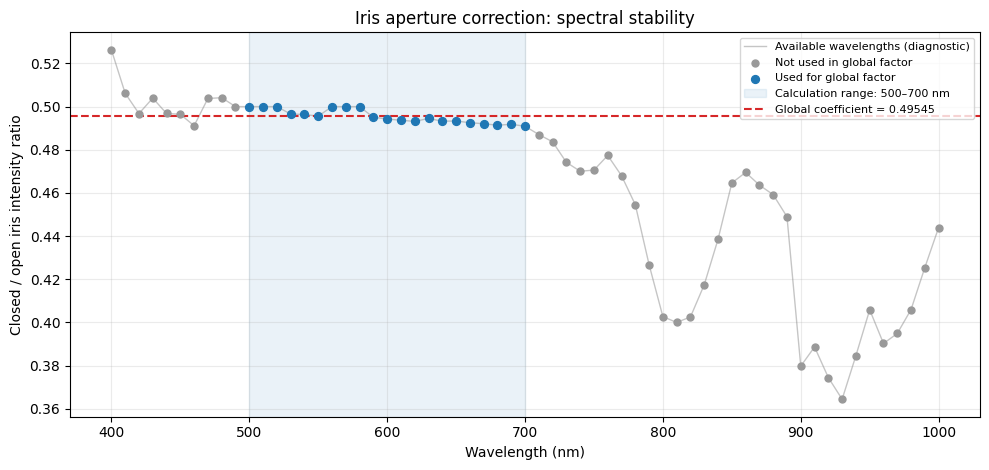

Correction multiplier (closed/open): 0.495446
Spectral CV (selected bands): 0.65%
Selected wavelengths: 21


In [2]:
from iris_aperture_calibration import calculate_iris_correction

if OPTIONS['use_iris_correction']:
    for study in selected_folders:
        print('IRIS CALIBRATION:', study)
        iris_result = calculate_iris_correction(
            study,
            open_marker=OPTIONS['iris_open_marker'],
            closed_marker=OPTIONS['iris_closed_marker'],
            stability_cv_warning=OPTIONS['iris_stability_cv_warning'],
            valid_dn_range=OPTIONS['iris_valid_dn_range'],
            wavelength_range=OPTIONS['iris_wavelength_range'],
            overwrite=False,
            show_plot=True,
        )
        if iris_result is not None:
            print(f"Correction multiplier (closed/open): {iris_result['coefficient']:.6f}")
            print(f"Spectral CV (selected bands): {iris_result['wavelength_cv']*100:.2f}%")
            print(f"Selected wavelengths: {iris_result['n_wavelengths']}")
        else:
            print('No matching iris pair; Stage 1 will skip iris correction.')
else:
    print("Iris correction is disabled (OPTIONS[\'use_iris_correction\'] = False).")


## Stage 1 — create corrected hyperspectral cubes

Runs calibration **without segmentation or index calculation**, applying an optional study-wide iris multiplier when the single open/closed reference pair exists. Existing cubes can be reused. The next stages read only the saved NPZ cubes.

In [3]:
stage1_reports={}
for study in selected_folders:
    print('CALIBRATION:',study)
    *_, report=process_wheat_study(study,**MARKERS,**OPTIONS,stop_after_cubes=True)
    stage1_reports[study.name]=report
    print(report[['sample','status','stage','error']].to_string(index=False))


CALIBRATION: d:\HS-heat-drought-rape-29.10.2026\wheat_pipeline_v6_curated_full\experiment_data
Dark correction: using single source 29.10.2026_dark_slides (mode=pixelwise)
[experiment_data] Using cached iris factor k=0.495446 (CV=0.65%, range=[500, 700] nm)
Processing: 29.10.2026_rape_erebus-1-1-cw
Processing: 29.10.2026_rape_erebus-1-2-cw
Processing: 29.10.2026_rape_erebus-1-3-cw
Processing: 29.10.2026_rape_erebus-2-1-cd
Processing: 29.10.2026_rape_erebus-2-2-cd
Processing: 29.10.2026_rape_erebus-2-3-cd
Processing: 29.10.2026_rape_erebus-3-1-hw
Processing: 29.10.2026_rape_erebus-3-2-hw
Processing: 29.10.2026_rape_erebus-3-3-hw
Processing: 29.10.2026_rape_erebus-4-1-hd
Processing: 29.10.2026_rape_erebus-4-2-hd
Processing: 29.10.2026_rape_erebus-4-3-hd
Processing: 29.10.2026_rape_prometei-1-1-cw
Processing: 29.10.2026_rape_prometei-1-2-cw
Processing: 29.10.2026_rape_prometei-1-3-cw
Processing: 29.10.2026_rape_prometei-2-1-cd
Processing: 29.10.2026_rape_prometei-2-2-cd
Processing: 29.10.

## Stage 2 — segmentation and creation of object masks

`segformer` produces an initial `masks/object_01.png` automatically. `sam` starts the interactive editor in the next cell: mark foreground/background points, click **Run SAM**, correct using the brush/eraser and **Save mask**. More masks can be saved as `object_02`, `object_03`, etc. For SAM, model weights are downloaded once to a directory beside the Python modules.

In [3]:
for study in selected_folders:
    if SEGMENTATION_MODEL == 'segformer':
        report=segment_samples(study,model='segformer',overwrite=False,
                               rgb_wavelengths=OPTIONS['rgb_wavelengths'],
                               classes=SEGFORMER_CLASSES,tile_size=2048,overlap=512)
        print(study.name,report)
    else:
        print(study.name, 'SAM / manual mode: open the editor in Stage 2a below')


experiment_data SAM / manual mode: open the editor in Stage 2a below


## Stage 2a — create or correct masks interactively

Execute the first cell to activate mouse interaction. Select **one sample** and optionally an existing `object_id`. **Cancel/Skip** closes without saving current edits. Masks already saved remain on disk. For multiple objects, use **New object**, add prompts or paint, and save. The editor never changes cubes or existing results until you save.

In [4]:
%matplotlib widget
all_samples=[p for study in selected_folders for p in find_samples(study)]
for i,p in enumerate(all_samples):print(i,p)


0 D:\HS-heat-drought-rape-29.10.2026\wheat_pipeline_v6_curated_full\experiment_data\29.10.2026_rape_erebus-1-1-cw
1 D:\HS-heat-drought-rape-29.10.2026\wheat_pipeline_v6_curated_full\experiment_data\29.10.2026_rape_erebus-1-2-cw
2 D:\HS-heat-drought-rape-29.10.2026\wheat_pipeline_v6_curated_full\experiment_data\29.10.2026_rape_erebus-1-3-cw
3 D:\HS-heat-drought-rape-29.10.2026\wheat_pipeline_v6_curated_full\experiment_data\29.10.2026_rape_erebus-2-1-cd
4 D:\HS-heat-drought-rape-29.10.2026\wheat_pipeline_v6_curated_full\experiment_data\29.10.2026_rape_erebus-2-2-cd
5 D:\HS-heat-drought-rape-29.10.2026\wheat_pipeline_v6_curated_full\experiment_data\29.10.2026_rape_erebus-2-3-cd
6 D:\HS-heat-drought-rape-29.10.2026\wheat_pipeline_v6_curated_full\experiment_data\29.10.2026_rape_erebus-3-1-hw
7 D:\HS-heat-drought-rape-29.10.2026\wheat_pipeline_v6_curated_full\experiment_data\29.10.2026_rape_erebus-3-2-hw
8 D:\HS-heat-drought-rape-29.10.2026\wheat_pipeline_v6_curated_full\experiment_data\29.1

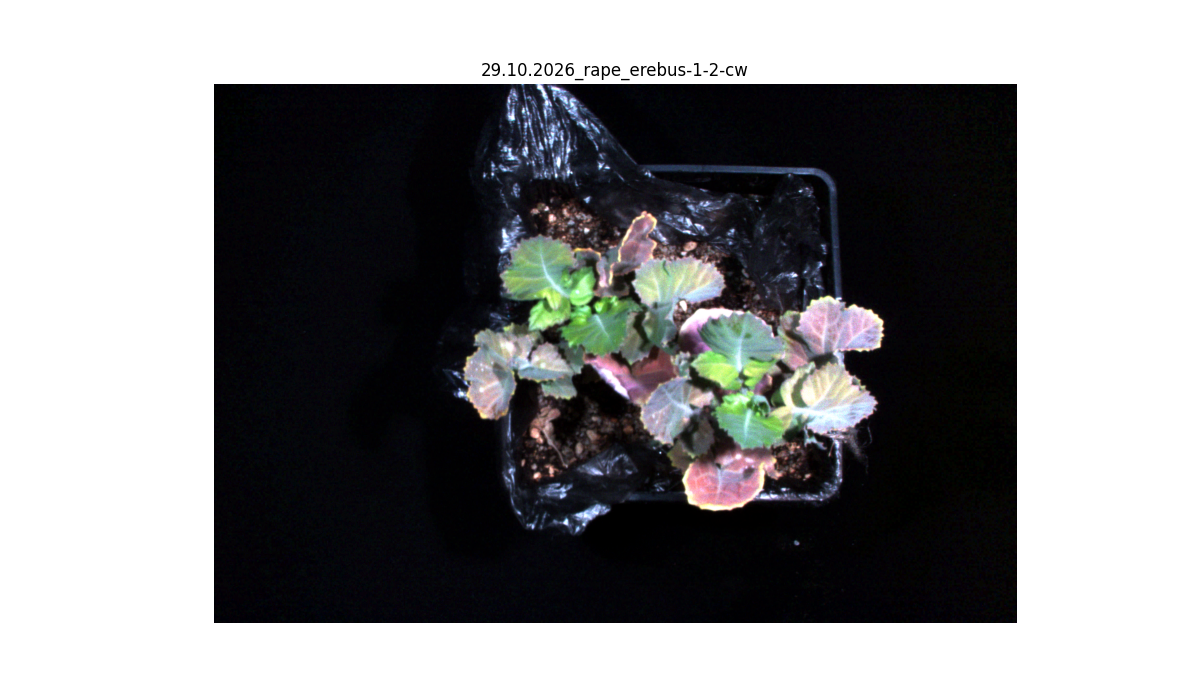

In [25]:
SAMPLE_INDEX=1
OBJECT_ID=None  # e.g. 'object_01' to edit an existing mask
if all_samples:
    editor=edit_mask(all_samples[SAMPLE_INDEX],object_id=OBJECT_ID,
                     rgb_wavelengths=OPTIONS['rgb_wavelengths'])
else:print('No corrected cubes yet. Run Stage 1 first.')


## Stage 3 — object analysis, spectra, indices, PCA, maps and collages

Only saved `corrected_cube.npz` and `masks/*.png` are used. To recalculate after manual changes, rerun **this cell only**. With no mask, the full valid image is analyzed; set `MASK_MODE="full"` or `MAP_MODE="full"` to explicitly ignore saved masks. Pixelwise index maps use one study-wide color scale for each index. Spatial PCA is fitted separately per cube, so PC colors are **not comparable across cubes**.
The `INDEX_PRESET` option controls both tables (`indices_raw.csv`, `indices_savgol.csv`) and heatmaps. Use `CUSTOM_INDICES` to override all presets.

Curated index set: **8 / 18 / 32 indices**. Original PRI 531/570 and MTCI 754/709/681 centers are linearly interpolated if needed; WBI is R970/R900 (original 1993 convention). Old V6 WBI/MTCI tables are not numerically equivalent; rerun this stage.


ANALYSIS: d:\HS-heat-drought-rape-29.10.2026\wheat_pipeline_v6_curated_full\experiment_data
Automatic K-means selection: K=2 (silhouette=0.487)
Index maps: 29.10.2026_rape_erebus-1-1-cw / 2 mask(s)
Index maps: 29.10.2026_rape_erebus-1-2-cw / 2 mask(s)
Index maps: 29.10.2026_rape_erebus-1-3-cw / 2 mask(s)
Index maps: 29.10.2026_rape_erebus-2-1-cd / 2 mask(s)
Index maps: 29.10.2026_rape_erebus-2-2-cd / 2 mask(s)
Index maps: 29.10.2026_rape_erebus-2-3-cd / 2 mask(s)
Index maps: 29.10.2026_rape_erebus-3-1-hw / 2 mask(s)
Index maps: 29.10.2026_rape_erebus-3-2-hw / 2 mask(s)
Index maps: 29.10.2026_rape_erebus-3-3-hw / 2 mask(s)
Index maps: 29.10.2026_rape_erebus-4-1-hd / 2 mask(s)
Index maps: 29.10.2026_rape_erebus-4-2-hd / 2 mask(s)
Index maps: 29.10.2026_rape_erebus-4-3-hd / 2 mask(s)
Index maps: 29.10.2026_rape_prometei-1-1-cw / 2 mask(s)
Index maps: 29.10.2026_rape_prometei-1-2-cw / 2 mask(s)
Index maps: 29.10.2026_rape_prometei-1-3-cw / 2 mask(s)
Index maps: 29.10.2026_rape_prometei-2-1

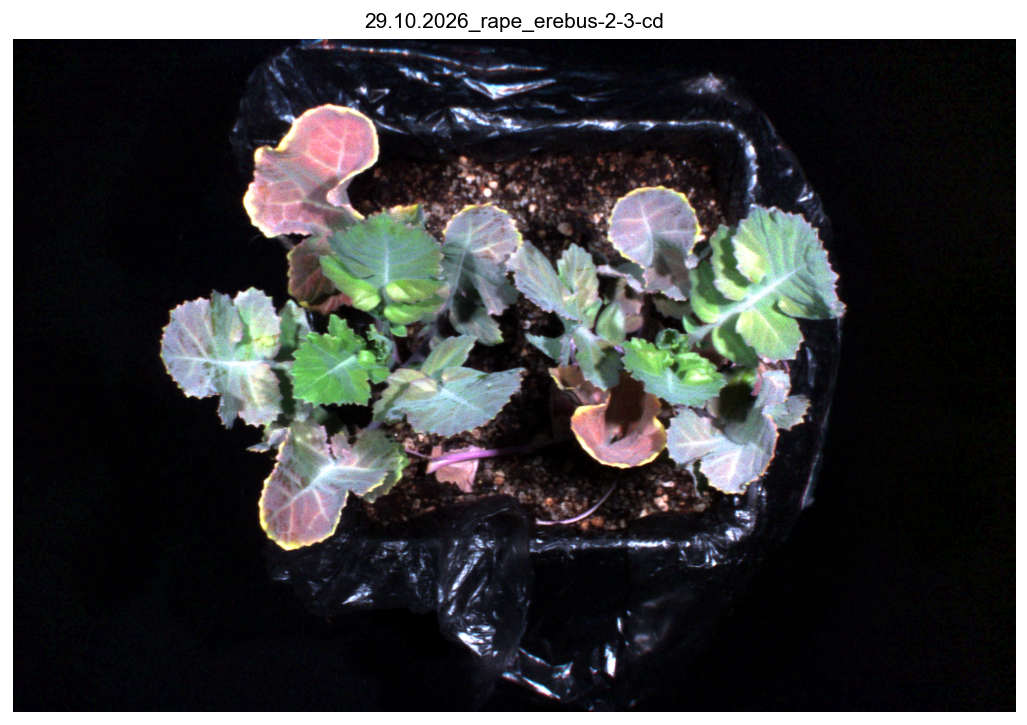

In [26]:
# Switch to noninteractive display for batch plotting, if desired:
%matplotlib inline
stage3_results={}
for study in selected_folders:
    print('ANALYSIS:',study)
    try:
        stage3_results[study.name]=analyze_study_objects(
            study,mask_mode=MASK_MODE,map_mode=MAP_MODE,
            sg_window=SG_WINDOW,sg_polyorder=SG_POLYORDER,
            n_pca_components=PCA_COMPONENTS,n_clusters='auto',
            data_type='reflectance' if OPTIONS['use_spectral_correction'] else 'signal',
            color_config_csv=COLOR_SCALE_CSV,empirical_strategy=EMPIRICAL_STRATEGY,
            indices=SELECTED_INDICES,index_preset=INDEX_PRESET,
            overwrite_maps=True,pca_maps=True,pca_map_mode=PCA_MAP_MODE)
    except Exception as ex:
        print('ERROR',study.name,type(ex).__name__,ex)


## Optional — regenerate only VI maps and collages

If mean spectra and object PCA results are already up to date, instead of rerunning the entire Stage 3, use `render_object_index_maps()` and rebuild collages via the main function. To regenerate everything that depends on changed masks, use Stage 3 above.

In [ ]:
# Example for a single study (uncomment):
# report=render_object_index_maps(selected_folders[0],mode='union',
#     indices=SELECTED_INDICES,
#     data_type='reflectance',scale_config=COLOR_SCALE_CSV,
#     empirical_strategy='robust',overwrite=True)
# display(report.head())
